# Sazonalidade do produto de maior lucro da LH Nautical

## Por que este produto

O **Cabo Náutico 5117** é o produto que **mais gerou lucro bruto de venda** para a LH Nautical: **R$ 1.579.792** em 771 unidades, 1,6% acima do segundo colocado (a tabela da seção 1 mostra os cinco primeiros).

Quando um único produto concentra tanto lucro, **acertar quando ele vende e quanto ter em estoque** protege o resultado da empresa:

- **faltar produto justamente nos meses de pico** faz a empresa perder o lucro que ele mais dá;
- **comprar demais nos meses fracos** prende dinheiro em estoque parado.

A análise de sazonalidade responde a isso: em que meses ele vende, se o padrão se repete, o que puxa os picos e o que acontece depois.

## Resposta curta

1. **Quando vende mais e menos:** janeiro e fevereiro (cerca de 17 unidades por mês em média) e novembro (13,5). Vende menos em **julho** (2 unidades por mês, sem nenhuma venda em 4 dos 7 anos), agosto e setembro (cerca de 5).
2. **Se repete todo ano:** o calendário é **comprovado** (chance de ser sorte de 2,2%), mas o contraste entre alta e baixa temporada só é claro **nas 3 últimas temporadas**: a alta vende cerca de 3 vezes a baixa. Em 2021 a 2023, alta e baixa eram parecidas.
3. **O que puxa os picos:** **mais pedidos, de clientes diferentes, em mais lojas no mesmo mês** (nos meses de pico foram, em média, 4,2 pedidos por mês em 2,9 lojas por mês; nos demais meses, 1,4 pedido em 1,2 loja por mês). Não foi preço (sempre o mesmo), nem desconto, nem pedidos maiores.
4. **Depois da alta:** no mês seguinte ao pico a demanda volta perto do normal (0,9 vez a média do ano); no segundo mês cai para menos da metade (0,4 vez). Na baixa temporada o produto vende cerca de **30% do que vende na alta**.
5. **Alerta:** o estoque registrado é de **16 unidades** (18/09/2026), o que cobre cerca de **1,4 mês** de venda, e a alta temporada começa em novembro.

## O caminho do notebook

1. **Qual produto e os dados**
2. **Quando ele vende mais e menos**
3. **Isso se repete todo ano?**
4. **O que aumenta nos meses de pico**
5. **Como ele se comporta depois da alta**
6. **Insights e recomendações para a LH Nautical**

No fim há um **apêndice** com o glossário dos termos e as limitações.

## Setup

In [1]:
import sys
from pathlib import Path


def _find_project_root(start: Path) -> Path:
    """Sobe a partir do diretório do notebook até achar a raiz do bundle (databricks.yml)."""
    for candidate in (start, *start.parents):
        if (candidate / "databricks.yml").exists():
            return candidate
    raise FileNotFoundError(f"databricks.yml não encontrado acima de {start}")


# Funciona no workspace (.bundle/.../files/notebooks/ml) e localmente.
PROJECT_ROOT = _find_project_root(Path.cwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pyspark.sql import functions as F

from src.analytics_ai.eda_common import complete_months
from src.analytics_ai.eda_seasonality import (
    HIGH_SEASON_MONTHS,
    MONTH_LABELS,
    month_summary,
    peak_profile,
    season_vs_offseason,
    seasonal_index,
    seasonal_ratios,
    seasonality_metrics,
    year_month_matrix,
)
from src.analytics_ai.ml_config import MlFeatureConfig

# No Databricks o notebook já expõe `spark`; localmente cria via Databricks Connect
# (defina DATABRICKS_PROFILE com o nome do seu profile em ~/.databrickscfg).
spark = globals().get("spark")
if spark is None:
    from src.ingestion.utils import build_spark_session

    spark = build_spark_session()

# Databricks e Jupyter injetam `display`; fora deles, cai para print.
display = globals().get("display", print)

plt.rcParams["figure.dpi"] = 100
CORES = ["#2E5C8A", "#E8874C", "#4C9A6A", "#B24C4C"]
COR_GERAL = "#7A7A7A"

config = MlFeatureConfig.from_environment_monthly()
gold = config.gold_table


def pt(x, casas=1):
    """Número no formato brasileiro (vírgula decimal)."""
    return f"{x:.{casas}f}".replace(".", ",")


def brl(x):
    """Valor em reais no formato brasileiro."""
    return "R$ " + f"{x:,.0f}".replace(",", ".")

## 1. Qual produto e os dados

O produto é o que **mais gerou lucro bruto de venda** no histórico: a soma do lucro estimado (`estimated_gross_profit`, já descontando descontos) dos pedidos **confirmados e pagos**, que é a mesma definição de demanda usada no projeto de previsão. O lucro serve **só para escolher** o produto; a análise em si é sobre **unidades vendidas**.

**Os dados**

- **Vendas mensais:** unidades por mês, somando as 6 lojas, só com meses completos (o primeiro mês de venda e o último mês do banco ficam de fora).
- **Pedidos:** cada linha de pedido do produto, com data, loja, cliente, canal, quantidade e desconto.
- **Estoque e compras:** movimentos de estoque e pedidos de compra do produto.

**Esta é a única sessão do Databricks do notebook** (poucas consultas pequenas). O resto roda em pandas.

In [3]:
lucro = (
    spark.table(gold("fact_order_items"))
    .filter(F.col("order_status").isin("confirmed", "paid"))
    .groupBy("sk_product")
    .agg(
        F.sum(F.col("estimated_gross_profit").cast("double")).alias("lucro_total"),
        F.sum(F.col("quantity_ordered").cast("double")).alias("unidades"),
    )
    .toPandas()
)
produtos = (
    spark.table(gold("dim_products"))
    .select(
        "sk_product",
        "sku",
        "product_name",
        "category_name",
        F.col("cost_price").cast("double").alias("cost_price"),
        F.col("sale_price").cast("double").alias("sale_price"),
    )
    .toPandas()
)
ranking = lucro.merge(produtos, on="sk_product").sort_values("lucro_total", ascending=False).reset_index(drop=True)
SK, NOME = ranking.loc[0, "sk_product"], ranking.loc[0, "product_name"]
LUCRO, UNIDADES = ranking.loc[0, "lucro_total"], ranking.loc[0, "unidades"]

top5 = pd.DataFrame(
    {
        "Posição": range(1, 6),
        "Produto": ranking["product_name"].head(5).values,
        "Categoria": ranking["category_name"].head(5).values,
        "Lucro bruto total": ranking["lucro_total"].head(5).map(brl).values,
        "Unidades vendidas": ranking["unidades"].head(5).astype(int).values,
    }
)
display(top5)
folga = ranking.loc[0, "lucro_total"] / ranking.loc[1, "lucro_total"] - 1
print(f"Produto escolhido: {NOME} (categoria {ranking.loc[0, 'category_name']}).")
print(f"Lucro bruto total de {brl(LUCRO)} em {UNIDADES:.0f} unidades; {pt(folga * 100)}% a mais que o segundo colocado ({ranking.loc[1, 'product_name']}).")
print(f"Preço de venda cadastrado: {brl(ranking.loc[0, 'sale_price'])} | custo: {brl(ranking.loc[0, 'cost_price'])}")

# Vendas mensais do produto e do negócio inteiro (meses completos).
def vendas_mensais(filtro=None):
    base = spark.table(config.source_table)
    base = base.filter(filtro) if filtro is not None else base
    return (
        complete_months(base, config.date_col)
        .groupBy(config.date_col)
        .agg(F.sum(F.col(config.target_col).cast("double")).alias("demand"))
        .toPandas()
        .assign(month=lambda d: pd.to_datetime(d[config.date_col]))
        .set_index("month")["demand"]
        .sort_index()
    )


y = vendas_mensais(F.col("sk_product") == SK)
y = y.reindex(pd.date_range(y.index.min(), y.index.max(), freq="MS"), fill_value=0.0)
negocio = vendas_mensais()

# Pedidos, lojas, clientes, estoque e compras do produto.
lojas = spark.table(gold("dim_locations")).select("sk_location", "location_name").toPandas()
clientes = spark.table(gold("dim_customers")).select("sk_customer", "person_type").toPandas()
pedidos = (
    spark.table(gold("fact_order_items"))
    .filter(F.col("sk_product") == SK)
    .select("sk_customer", "sk_location", "channel", "order_status", "quantity_ordered", "unit_price", "gross_line_total", "allocated_discount_amount", "placed_at")
    .toPandas()
    .merge(lojas, on="sk_location", how="left")
    .merge(clientes, on="sk_customer", how="left")
)
estoque = spark.table(gold("fact_stock_movements")).filter(F.col("sk_product") == SK).select("occurred_at", "movement_type", "quantity", "is_legacy_migration").toPandas()
compras = (
    spark.table(gold("fact_purchase_order_items")).filter(F.col("sk_product") == SK).select("placed_at", "quantity_ordered", "purchase_order_status").toPandas()
)

print(f"\nSérie mensal: {y.index.min():%m/%Y} a {y.index.max():%m/%Y} ({len(y)} meses) | {y.sum():.0f} unidades | média de {pt(y.mean())} por mês")
print(f"Meses sem nenhuma venda: {int((y == 0).sum())} de {len(y)} ({(y == 0).mean() * 100:.0f}%)")

,Posição,Produto,Categoria,Lucro bruto total,Unidades vendidas
0,1,Cabo Náutico 5117,Cabos,R$ 1.579.792,771
1,2,Colete Salva-Vidas 3398,Coletes Salva-Vidas,R$ 1.555.476,802
2,3,Colete Salva-Vidas 2374,Coletes Salva-Vidas,R$ 1.517.223,890
3,4,Cabo Náutico 5921,Cabos,R$ 1.497.601,815
4,5,Bússola de Bordo 1248,Instrumentos de Navegação,R$ 1.485.699,741


Produto escolhido: Cabo Náutico 5117 (categoria Cabos).
Lucro bruto total de R$ 1.579.792 em 771 unidades; 1,6% a mais que o segundo colocado (Colete Salva-Vidas 3398).
Preço de venda cadastrado: R$ 4.027 | custo: R$ 1.891



Série mensal: 04/2020 a 08/2026 (77 meses) | 724 unidades | média de 9,4 por mês
Meses sem nenhuma venda: 18 de 77 (23%)


**Leitura:** o produto vende em média 9,4 unidades por mês, mas **23% dos meses não têm nenhuma venda**. É uma demanda **irregular**: poucos pedidos por mês, alguns de até 10 unidades. Por isso olhamos o padrão ao longo de vários anos, e não em um mês só.

A folga do primeiro para o segundo colocado é pequena (1,6%). Se o critério de "lucro" mudasse um pouco (por exemplo, lucro por unidade), o produto escolhido poderia ser outro.

## 2. Quando ele vende mais e menos

Para cada mês do ano (todos os janeiros, todos os fevereiros...), calculamos a **média de unidades vendidas**. As barras mostram essa média e os **pontos pretos mostram cada ano**, para você ver se a média é típica ou puxada por um ano só. A linha tracejada é a média geral de todos os meses.

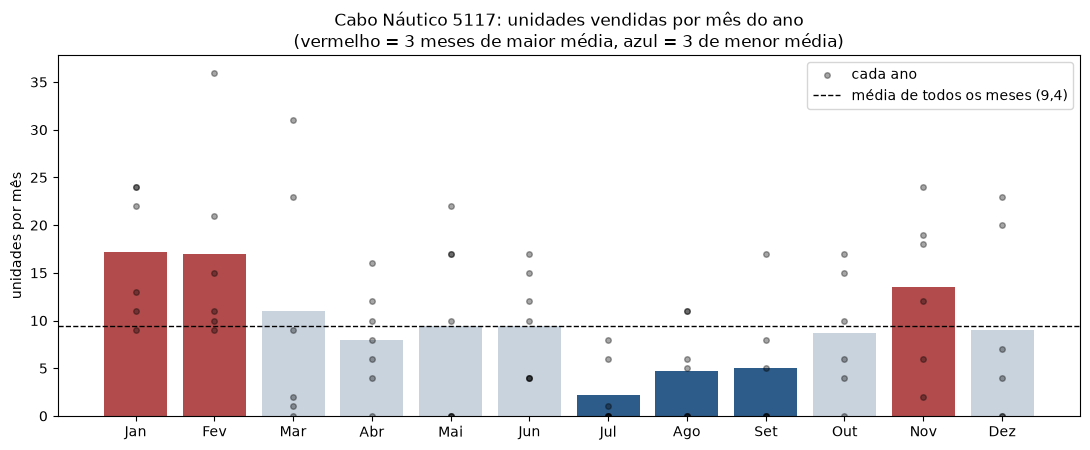

,Grupo,Média,Mediana,Anos observados,Anos em que ficou acima da média do ano
Jan,maior demanda,17.2,17.5,6,5
Fev,maior demanda,17.0,13.0,6,5
Nov,maior demanda,13.5,15.0,6,4
Jul,menor demanda,2.1,0.0,7,1
Ago,menor demanda,4.7,5.0,7,1
Set,menor demanda,5.0,2.5,6,2


Os 6 meses da alta temporada (nov a abr) concentram 64% das unidades (50% seria uma distribuição uniforme).


In [4]:
matriz = year_month_matrix(y)
resumo = month_summary(matriz)
resumo.index = MONTH_LABELS
mais = resumo["media"].nlargest(3).index
menos = resumo["media"].nsmallest(3).index

fig, ax = plt.subplots(figsize=(11, 4.6))
cores_barras = [CORES[3] if m in mais else CORES[0] if m in menos else "#C9D3DE" for m in resumo.index]
ax.bar(resumo.index, resumo["media"], color=cores_barras)
for ano, linha in matriz.iterrows():
    ax.scatter(MONTH_LABELS, linha.values, s=16, color="black", alpha=0.35, zorder=3, label="cada ano" if ano == matriz.index[0] else None)
ax.axhline(y.mean(), color="black", linestyle="--", linewidth=1, label=f"média de todos os meses ({pt(y.mean())})")
ax.set_title(f"{NOME}: unidades vendidas por mês do ano\n(vermelho = 3 meses de maior média, azul = 3 de menor média)")
ax.set_ylabel("unidades por mês")
ax.legend()
plt.tight_layout()
plt.show()

tabela_meses = resumo.loc[list(mais) + list(menos)].rename(
    columns={"media": "Média", "mediana": "Mediana", "anos": "Anos observados", "anos_acima": "Anos em que ficou acima da média do ano"}
)
tabela_meses.insert(0, "Grupo", ["maior demanda"] * 3 + ["menor demanda"] * 3)
display(tabela_meses.round(1))
por_alta = y[y.index.month.isin(HIGH_SEASON_MONTHS)].sum() / y.sum()
print(f"Os 6 meses da alta temporada (nov a abr) concentram {por_alta * 100:.0f}% das unidades (50% seria uma distribuição uniforme).")

**O que o gráfico e a tabela mostram**

- **Maior demanda:** **janeiro** (17,2 unidades por mês, em média) e **fevereiro** (17,0), seguidos de **novembro** (13,5). Nos três, a média ficou acima da média do próprio ano em 5 de 6 anos (janeiro e fevereiro) e 4 de 6 (novembro).
- **Menor demanda:** **julho** (2,1), **agosto** (4,7) e **setembro** (5,0). Julho tem mediana zero e ficou acima da média do ano em apenas 1 de 7 anos.
- **A alta temporada (nov a abr) concentra 64% das unidades**, contra 50% se a venda fosse uniforme.
- **Cuidado com março:** a média é 11,0, mas os pontos vão de 0 a 31. Um ou dois anos muito fortes puxam a média: março ficou acima da média do próprio ano em apenas 2 de 6 anos.

## 3. Isso se repete todo ano?

Três formas de conferir:

1. **Mapa ano × mês** (gráfico): cada célula é um mês de um ano, com o número de unidades. **Se o padrão se repete, as mesmas colunas ficam escuras em todos os anos.**
2. **Alta × baixa temporada, ano a ano** (tabela): compara a média mensal de **novembro a abril** com a de **maio a outubro** em cada temporada. Uma temporada começa em novembro do ano anterior (a de 2024 é nov/2023 a abr/2024 mais mai a out/2024).
3. **O teste de acaso:** toda série tem meses bons e ruins por sorte. Embaralhamos os meses 500 vezes para ver se o padrão que encontramos é maior do que a sorte produz. O resultado é a **chance de ser sorte** (p-valor): abaixo de 5%, consideramos o calendário **comprovado**.

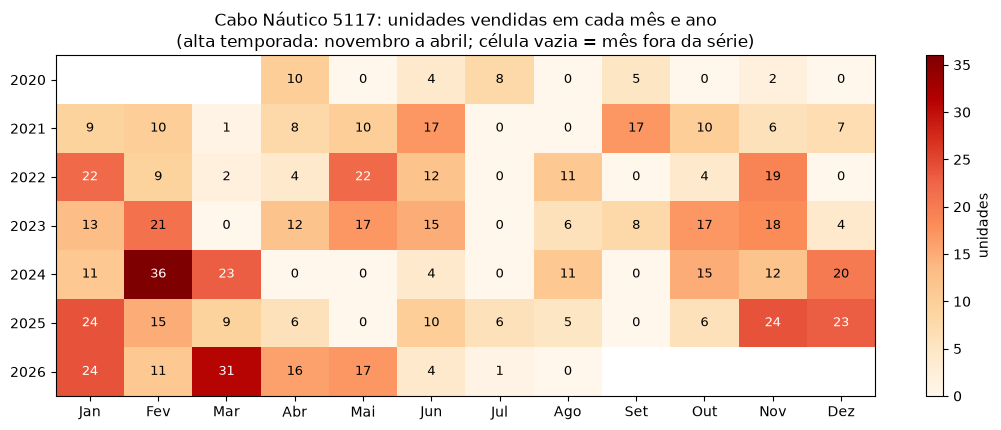

,Temporada,Meses de alta,Média mensal na alta (nov-abr),Meses de baixa,Média mensal na baixa (mai-out),Alta ÷ baixa
0,2020,1,10.0,6,2.8,NaN
1,2021,6,5.0,6,9.0,0.6
2,2022,6,8.3,6,8.2,1.0
3,2023,6,10.8,6,10.5,1.0
4,2024,6,15.3,6,5.0,3.1
5,2025,6,14.3,6,4.5,3.2
6,2026,6,21.5,4,5.5,3.9


Nota de sazonalidade (força sazonal x 100): 35 de 100 | esperada só pelo acaso: ~17
Chance de ser sorte (p-valor): 2,2%
Correlação com o calendário do negócio inteiro: 0,57 (1 = mesmo desenho)
Mês de pico do produto: Fev (índice 1,88) | mês de vale: Jul (índice 0,12)
Mês de pico do negócio: Jan (índice 1,74) | mês de vale: Jul (índice 0,41)


In [5]:
fig, ax = plt.subplots(figsize=(11, 4.4))
im = ax.imshow(np.ma.masked_invalid(matriz.values), cmap="OrRd", aspect="auto", vmin=0)
ax.set_xticks(range(12), MONTH_LABELS)
ax.set_yticks(range(len(matriz)), matriz.index)
for i in range(matriz.shape[0]):
    for j in range(12):
        valor = matriz.iloc[i, j]
        if not np.isnan(valor):
            ax.text(j, i, f"{valor:.0f}", ha="center", va="center", fontsize=9, color="white" if valor > 0.6 * np.nanmax(matriz.values) else "black")
ax.set_title(f"{NOME}: unidades vendidas em cada mês e ano\n(alta temporada: novembro a abril; célula vazia = mês fora da série)")
fig.colorbar(im, ax=ax, label="unidades")
plt.tight_layout()
plt.show()

temporadas = season_vs_offseason(y)
temporadas["razao"] = (temporadas["media_alta"] / temporadas["media_baixa"]).where((temporadas["meses_alta"] >= 3) & (temporadas["meses_baixa"] >= 3))
tabela_temp = pd.DataFrame(
    {
        "Temporada": temporadas.index,
        "Meses de alta": temporadas["meses_alta"].astype(int).values,
        "Média mensal na alta (nov-abr)": temporadas["media_alta"].round(1).values,
        "Meses de baixa": temporadas["meses_baixa"].astype(int).values,
        "Média mensal na baixa (mai-out)": temporadas["media_baixa"].round(1).values,
        "Alta ÷ baixa": temporadas["razao"].round(1).values,
    }
)
display(tabela_temp)

indice_negocio = seasonal_index(seasonal_ratios(negocio))
teste = seasonality_metrics(y, indice_negocio)
print(f"Nota de sazonalidade (força sazonal x 100): {teste['strength'] * 100:.0f} de 100 | esperada só pelo acaso: ~{teste['null_mean'] * 100:.0f}")
print(f"Chance de ser sorte (p-valor): {pt(teste['p_value'] * 100)}%")
print(f"Correlação com o calendário do negócio inteiro: {pt(teste['corr_global'], 2)} (1 = mesmo desenho)")
print(f"Mês de pico do produto: {MONTH_LABELS[teste['peak_month'] - 1]} (índice {pt(teste['peak_index'], 2)}) | mês de vale: {MONTH_LABELS[teste['trough_month'] - 1]} (índice {pt(teste['trough_index'], 2)})")
print(f"Mês de pico do negócio: {MONTH_LABELS[int(indice_negocio.idxmax()) - 1]} (índice {pt(indice_negocio.max(), 2)}) | mês de vale: {MONTH_LABELS[int(indice_negocio.idxmin()) - 1]} (índice {pt(indice_negocio.min(), 2)})")

**O que o mapa e as tabelas mostram**

- **Os mesmos meses se repetem:** janeiro e fevereiro ficam acima da média do ano em 5 de 6 anos, e **julho é fraco quase todo ano** (zero unidades em 2021, 2022, 2023 e 2024).
- **Mas a alta temporada nem sempre foi mais forte que a baixa.** Em 2021 a baixa vendeu mais (média de 9,0 contra 5,0 na alta). Em 2022 e 2023 ficaram iguais (cerca de 8 e 10 unidades nas duas). **A partir de 2024**, a alta passou a vender **3,1 a 3,9 vezes** a baixa (15,3 contra 5,0 em 2024; 14,3 contra 4,5 em 2025; 21,5 contra 5,5 em 2026).
- **O teste confirma que não é sorte:** a nota de sazonalidade é 35 (o acaso produz cerca de 17) e a chance de ser sorte é de **2,2%**, abaixo de 5%. Mas esse resultado vem sobretudo das três últimas temporadas.
- **O calendário do produto é parecido com o do negócio, mas não igual** (correlação de 0,57). O negócio inteiro tem pico em janeiro e vale em julho; o produto tem pico em fevereiro e um vale bem mais fundo em julho (índice 0,12, contra 0,41 do negócio).

**Resposta à pergunta "ocorre em todos os anos?":** o desenho básico (forte no início do ano, fraco em julho) aparece em quase todos os anos, mas **o contraste forte é recente**. Usar a média dos 6 anos subestima a diferença atual entre alta e baixa.

## 4. O que aumenta nos meses de pico

Se a venda sobe em certos meses, **o que muda naqueles meses**? Comparamos os **meses de pico** (o 10% de meses com mais unidades) com os demais, olhando cada pedido: quantos pedidos, de quantos clientes, em quantas lojas, de que tamanho, com desconto ou não. **Os números da tabela são médias por mês** (por isso aparecem com vírgula). Depois olhamos o **preço** e o **estoque**.

In [6]:
linhas = pedidos[pedidos["order_status"].isin(["confirmed", "paid"])].copy()
linhas["mes"] = pd.to_datetime(linhas["placed_at"]).dt.to_period("M").dt.to_timestamp()
linhas = linhas[linhas["mes"].isin(y.index)]
linhas["q"] = linhas["quantity_ordered"].astype(float)
linhas["desconto"] = linhas["allocated_discount_amount"].astype(float) > 0
linhas["desconto_pct"] = linhas["allocated_discount_amount"].astype(float) / linhas["gross_line_total"].astype(float) * 100

por_mes = linhas.groupby("mes").agg(
    pedidos=("q", "size"),
    clientes=("sk_customer", "nunique"),
    lojas=("location_name", "nunique"),
    por_pedido=("q", "mean"),
    com_desconto=("desconto", "mean"),
    pj=("person_type", lambda s: (s == "pj").mean()),
    ecommerce=("channel", lambda s: (s == "ecommerce").mean()),
).reindex(y.index)
por_mes["unidades"] = y
por_mes[["pedidos", "clientes", "lojas"]] = por_mes[["pedidos", "clientes", "lojas"]].fillna(0)

limite = y.quantile(0.9)
eh_pico = y >= limite
colunas = {
    "unidades": "Unidades no mês",
    "pedidos": "Pedidos",
    "clientes": "Clientes diferentes",
    "lojas": "Lojas diferentes",
    "por_pedido": "Unidades por pedido",
    "com_desconto": "% dos pedidos com desconto",
    "pj": "% de clientes pessoa jurídica",
    "ecommerce": "% pelo e-commerce",
}
comparacao = pd.DataFrame(
    {
        f"Meses de pico ({int(eh_pico.sum())})": por_mes.loc[eh_pico, list(colunas)].mean(),
        f"Demais meses ({int((~eh_pico).sum())})": por_mes.loc[~eh_pico, list(colunas)].mean(),
    }
).rename(index=colunas)
comparacao.loc[["% dos pedidos com desconto", "% de clientes pessoa jurídica", "% pelo e-commerce"]] *= 100
display(comparacao.round(1))

maiores = por_mes.sort_values("unidades", ascending=False).head(6)
display(
    pd.DataFrame(
        {
            "Mês": [f"{m:%m/%Y}" for m in maiores.index],
            "Unidades": maiores["unidades"].astype(int).values,
            "Pedidos": maiores["pedidos"].astype(int).values,
            "Lojas diferentes": maiores["lojas"].astype(int).values,
            "Unidades por pedido": maiores["por_pedido"].round(1).values,
            "% com desconto": (maiores["com_desconto"] * 100).round(0).values,
        }
    )
)

por_ano = por_mes.groupby(por_mes.index.year).agg(
    unidades=("unidades", "sum"), pedidos_por_mes=("pedidos", "mean"), lojas_por_mes=("lojas", "mean"), com_desconto=("com_desconto", "mean")
)
por_ano["com_desconto"] *= 100
display(
    por_ano.rename(
        columns={"unidades": "Unidades no ano", "pedidos_por_mes": "Pedidos por mês", "lojas_por_mes": "Lojas por mês", "com_desconto": "% com desconto"}
    ).round(1)
)
preco = linhas["unit_price"].astype(float)
print(f"Preço unitário praticado: {preco.nunique()} valor distinto ({brl(preco.iloc[0])}), igual ao preço cadastrado.")
print(f"Pedidos com desconto: {linhas['desconto'].mean() * 100:.0f}% (desconto médio de {pt(linhas.loc[linhas['desconto'], 'desconto_pct'].mean())}% nesses pedidos).")
canal = linhas.groupby("channel")["q"].sum() / linhas["q"].sum()
print(f"Canais (fração das unidades): e-commerce {canal.get('ecommerce', 0) * 100:.0f}%, loja física (pos) {canal.get('pos', 0) * 100:.0f}%.")

,Meses de pico (9),Demais meses (68)
Unidades no mês,25.4,7.3
Pedidos,4.2,1.4
Clientes diferentes,4.2,1.4
Lojas diferentes,2.9,1.2
Unidades por pedido,6.1,5.2
% dos pedidos com desconto,20.4,27.3
% de clientes pessoa jurídica,40.0,47.5
% pelo e-commerce,72.4,75.8


,Mês,Unidades,Pedidos,Lojas diferentes,Unidades por pedido,% com desconto
0,02/2024,36,5,5,7.2,0.0
1,03/2026,31,5,2,6.2,20.0
2,01/2025,24,5,4,4.8,60.0
3,11/2025,24,5,3,4.8,20.0
4,01/2026,24,4,2,6.0,0.0
5,12/2025,23,3,2,7.7,33.0


,Unidades no ano,Pedidos por mês,Lojas por mês,% com desconto
2020,29.0,1.0,1.0,8.3
2021,95.0,1.4,1.2,38.3
2022,105.0,1.7,1.3,25.0
2023,131.0,1.8,1.2,36.7
2024,132.0,2.0,1.8,14.6
2025,128.0,2.2,1.8,29.7
2026,104.0,2.2,1.4,19.5


Preço unitário praticado: 1 valor distinto (R$ 4.027), igual ao preço cadastrado.
Pedidos com desconto: 24% (desconto médio de 8,2% nesses pedidos).
Canais (fração das unidades): e-commerce 78%, loja física (pos) 22%.


**E o estoque?** Um pico de venda pode ser limitado (ou ajudado) pelo que havia em estoque. O gráfico mostra as vendas de cada mês e o **saldo de estoque registrado** (soma de todas as lojas). Os pontos verdes são as datas em que chegou mercadoria comprada.

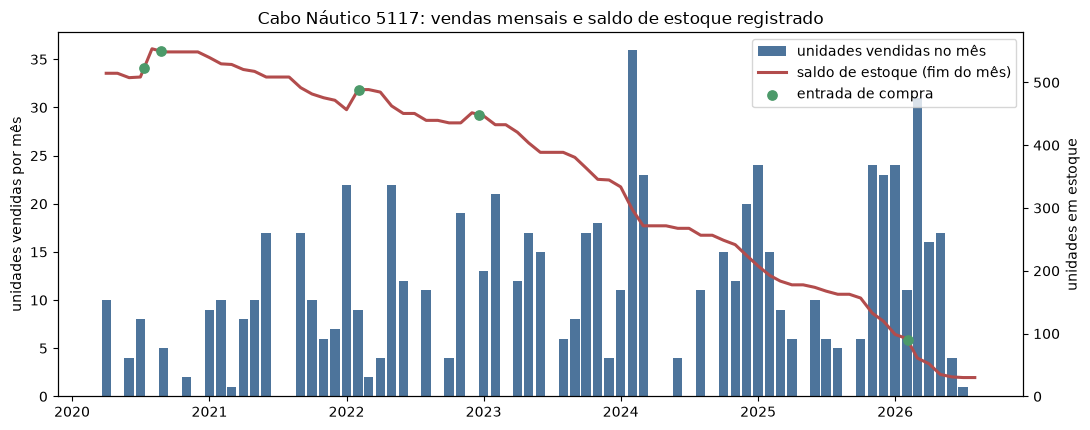

Saldo registrado no último movimento (18/09/2026): 16 unidades | estoque inicial (migração): 547
Ritmo de venda dos últimos 6 meses: 11,5 unidades por mês, ou seja, o saldo cobre cerca de 1,4 meses.
Entradas de compra no período (fora o saldo inicial): 5 (113 unidades)
Pedidos de compra registrados: 5 | status: {'received': 3, 'partially_received': 2}


In [7]:
mov = estoque.copy()
mov["t"] = pd.to_datetime(mov["occurred_at"])
mov["quantity"] = mov["quantity"].astype(float)
mov = mov.sort_values("t")
mov["saldo"] = mov["quantity"].cumsum()
saldo_mensal = mov.set_index("t")["saldo"].resample("MS").last().ffill().reindex(y.index).ffill()
entradas = mov[(mov["movement_type"] == "purchase_in") & ~mov["is_legacy_migration"].astype(bool)]

fig, ax = plt.subplots(figsize=(11, 4.4))
ax.bar(y.index, y.values, width=25, color=CORES[0], alpha=0.85, label="unidades vendidas no mês")
ax.set_ylabel("unidades vendidas por mês")
ax2 = ax.twinx()
ax2.plot(saldo_mensal.index, saldo_mensal.values, color=CORES[3], linewidth=2.2, label="saldo de estoque (fim do mês)")
ax2.scatter(entradas["t"], np.interp(entradas["t"].map(pd.Timestamp.toordinal), saldo_mensal.index.map(pd.Timestamp.toordinal), saldo_mensal.values), color=CORES[2], s=45, zorder=4, label="entrada de compra")
ax2.set_ylabel("unidades em estoque")
ax2.set_ylim(bottom=0)
linhas_leg = ax.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
rotulos_leg = ax.get_legend_handles_labels()[1] + ax2.get_legend_handles_labels()[1]
ax.legend(linhas_leg, rotulos_leg, loc="upper right")
ax.set_title(f"{NOME}: vendas mensais e saldo de estoque registrado")
plt.tight_layout()
plt.show()

saldo_atual = mov["saldo"].iloc[-1]
ritmo = y.tail(6).mean()
print(f"Saldo registrado no último movimento ({mov['t'].max():%d/%m/%Y}): {saldo_atual:.0f} unidades | estoque inicial (migração): {mov.loc[mov['is_legacy_migration'].astype(bool), 'quantity'].sum():.0f}")
print(f"Ritmo de venda dos últimos 6 meses: {pt(ritmo)} unidades por mês, ou seja, o saldo cobre cerca de {pt(saldo_atual / ritmo)} meses.")
print(f"Entradas de compra no período (fora o saldo inicial): {len(entradas)} ({entradas['quantity'].sum():.0f} unidades)")
print(f"Pedidos de compra registrados: {len(compras)} | status: {compras['purchase_order_status'].value_counts().to_dict()}")

**O que as tabelas e o gráfico mostram**

- **O que muda nos meses de pico:** quase tudo é **quantidade de gente comprando**. Nos 9 meses de pico houve de 3 a 5 pedidos por mês (**média de 4,2**), cada um de um cliente diferente, feitos em 2 a 5 lojas por mês (**média de 2,9**). Nos 68 demais meses, a média é de 1,4 pedido por mês, cada um de um cliente diferente, em 1,2 loja. **Os números com vírgula são médias por mês; em cada mês, pedidos, clientes e lojas são sempre números inteiros.** Cada pedido de pico tem tamanho parecido (6,1 unidades, contra 5,2).
- **Não é desconto:** 20% dos pedidos dos meses de pico tiveram desconto, contra 27% nos demais. O preço unitário foi **sempre o mesmo** (R$ 4.027), e o desconto médio, quando existe, é de 8,2%.
- **Não é canal nem tipo de cliente:** o e-commerce responde por 72% dos pedidos nos picos e 76% nos demais; a proporção de pessoa jurídica é de 40% e cerca de 48%.
- **Os maiores meses** (02/2024 com 36 unidades, 03/2026 com 31) vieram de **5 pedidos cada um, em 5 e em 2 lojas**, com 0% e 20% dos pedidos com desconto.
- **Uma mudança a partir de 2024:** os pedidos por mês subiram de 1,4 (2021) para 2,0 (2024) e 2,2 (2025), e as lojas com venda por mês, de 1,2 para **1,8 em 2024 e 2025**. A venda passou a se espalhar por mais lojas, e isso coincide com o contraste maior entre alta e baixa.
- **O estoque não limitou a venda até aqui, e agora limita:** o estoque começou em 547 unidades (migração de jan/2020) e desceu quase sem reposição (5 entradas de compra em 6 anos, 113 unidades). O saldo registrado em 18/09/2026 é de **16 unidades**, cerca de **1,4 mês** no ritmo dos últimos 6 meses (11,5 unidades por mês). Dos 5 pedidos de compra registrados, 3 foram recebidos e 2 ficaram parcialmente recebidos.

**Fatores que podem ter ajudado nos aumentos** (sugeridos pelos dados, a confirmar com o comercial): a **alta temporada náutica** (nov a abr), **mais lojas vendendo o produto ao mesmo tempo** e **mais clientes por mês**. Preço, desconto e pedidos maiores **não** explicam.

## 5. Como ele se comporta depois da alta

Duas perguntas: **(a)** depois do mês mais forte de cada ano, a venda cai quanto e em quanto tempo volta ao normal? **(b)** depois de toda a alta temporada, quanto a demanda cai?

Para (a), pegamos o **mês de pico de cada ano completo** e medimos os meses ao redor dele em comparação com a **média mensal daquele ano**: **1,0** = mês normal, **2,0** = o dobro, **0,5** = metade. O mês 0 é o pico.

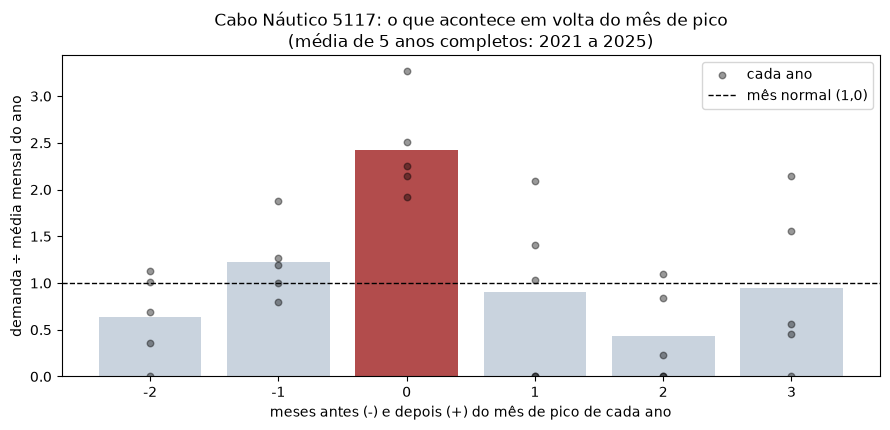

,Mês de pico,-2,-1,0 (pico),+1,+2,+3
2021,Jun,1.01,1.26,2.15,0.00,0.00,2.15
2022,Jan,0.69,0.80,2.51,1.03,0.23,0.46
2023,Fev,0.00,1.19,1.92,0.00,1.10,1.56
2024,Fev,0.36,1.00,3.27,2.09,0.00,0.00
2025,Jan,1.12,1.88,2.25,1.41,0.84,0.56


Média mensal da baixa (mai-out) como % da média da alta (nov-abr), por temporada completa:
{2021: '180%', 2022: '98%', 2023: '97%', 2024: '33%', 2025: '31%', 2026: '26%'}


In [8]:
perfil = peak_profile(y)
desloc = [c for c in perfil.columns if c != "mes_pico"]
media_perfil = perfil[desloc].mean()

fig, ax = plt.subplots(figsize=(9, 4.4))
ax.bar([str(k) for k in desloc], media_perfil.values, color=[CORES[3] if k == 0 else "#C9D3DE" for k in desloc])
for ano, linha in perfil[desloc].iterrows():
    ax.scatter([str(k) for k in desloc], linha.values, s=22, color="black", alpha=0.4, zorder=3, label="cada ano" if ano == perfil.index[0] else None)
ax.axhline(1, color="black", linestyle="--", linewidth=1, label="mês normal (1,0)")
ax.set_xlabel("meses antes (-) e depois (+) do mês de pico de cada ano")
ax.set_ylabel("demanda ÷ média mensal do ano")
ax.set_title(f"{NOME}: o que acontece em volta do mês de pico\n(média de {len(perfil)} anos completos: {perfil.index.min()} a {perfil.index.max()})")
ax.legend()
plt.tight_layout()
plt.show()

tabela_perfil = perfil.copy()
tabela_perfil.insert(0, "Mês de pico", tabela_perfil.pop("mes_pico").map(lambda m: MONTH_LABELS[int(m) - 1]))
display(tabela_perfil.rename(columns={k: f"{k:+d}" if k else "0 (pico)" for k in desloc}).round(2))

completas = temporadas[(temporadas["meses_alta"] == 6) & (temporadas["meses_baixa"] >= 4)]
queda = (1 - completas["media_baixa"] / completas["media_alta"]) * 100
print("Média mensal da baixa (mai-out) como % da média da alta (nov-abr), por temporada completa:")
print({int(t): f"{pt(v, 0)}%" for t, v in (100 - queda).items()})

**O que o gráfico e a tabela mostram**

- **O pico é curto, e não uma temporada sustentada.** No mês de pico o produto vende em média **2,4 vezes** o mês normal.
- **Antes:** o mês anterior já é um pouco mais forte que o normal (1,2 vez), e dois meses antes é mais fraco (0,6 vez).
- **Depois:** no mês seguinte a demanda volta **perto do normal** em média (0,9 vez), mas com muita variação: de nenhuma venda a 2,1 vezes. **No segundo mês cai para menos da metade** (0,4 vez, com nenhuma venda em 2 dos 5 anos) e no terceiro volta a 0,9 vez.
- **Na baixa temporada inteira** (maio a outubro), a média mensal é de **33%, 31% e 26%** da média da alta nas três últimas temporadas (2024, 2025 e 2026). Em 2021 a baixa foi maior que a alta (180%), e em 2022 e 2023 ficou igual (98% e 97%), o que reforça que o contraste é recente.
- **Cuidado:** o perfil usa só 5 anos completos (2021 a 2025), e o pico de 2021 caiu em junho (17 unidades, empatado com setembro), um ano sem alta temporada clara. Em 2022, janeiro também empata com maio (22 unidades). Em 2025, janeiro empata com novembro (24 unidades). Os pontos do gráfico mostram como cada ano varia.

## 6. Insights e recomendações para a LH Nautical

Cada item vem marcado: **[dado]** sai direto das tabelas e gráficos; **[a confirmar]** é uma leitura de negócio que precisa ser confirmada com o time comercial ou com mais análise.

### Insights

1. **[dado] O calendário é real, mas é recente.** O produto tem sazonalidade comprovada (2,2% de chance de ser sorte), porém a alta temporada só vendeu bem mais que a baixa nas **três últimas temporadas** (cerca de 3 vezes). Em 2021 a 2023 as duas eram parecidas. A média de 6 anos **subestima** o contraste atual, então a referência mais útil é a dos últimos 3 anos.
2. **[dado] Ele vende sobretudo na alta temporada (novembro a abril) e quase nada em julho.** A alta temporada concentra 64% das unidades, janeiro e fevereiro lideram (17 por mês) e julho ficou sem nenhuma venda em 4 dos 7 anos.
3. **[dado] Os picos são de muita gente comprando ao mesmo tempo, não de promoção.** Nos meses de pico há, em média, 4,2 pedidos por mês, todos de clientes diferentes, em 2,9 lojas por mês; o preço é fixo e os descontos são menos frequentes que nos demais meses. **A demanda é orgânica e depende de muitas lojas venderem no mesmo mês.**
4. **[dado] Depois do pico, a demanda cai rápido.** Volta perto do normal no mês seguinte e cai a menos da metade no segundo mês; na baixa temporada o produto vende cerca de 30% do que vende na alta.
5. **[dado] O estoque é o ponto de atenção.** Com 16 unidades registradas e ritmo de 11,5 por mês, o saldo cobre cerca de 1,4 mês. **A alta temporada começa em novembro**, e nas três últimas a média mensal foi de 14 a 21,5 unidades.

### Recomendações

1. **[a confirmar] Repor o estoque antes de novembro.** Como ordem de grandeza, 6 meses de alta a 14 a 21 unidades por mês dão **cerca de 85 a 130 unidades**. É preciso conferir o prazo de entrega do fornecedor (dos 5 pedidos de compra registrados, 2 foram recebidos só parcialmente).
2. **[a confirmar] Planejar compra e estoque pelo calendário dos últimos 3 anos**, e não pela média histórica de 6 anos.
3. **[a confirmar] Comprar pouco entre junho e setembro**, com julho perto de zero, para não prender dinheiro em estoque parado.
4. **[a confirmar] Acompanhar o número de lojas e de pedidos no mês** como sinal antecipado: os meses de pico têm, em média, cerca de 4 pedidos em 3 lojas.

### Perguntas em aberto

- **Por que o padrão só ficou claro a partir de 2024?** A base de lojas que vende o produto aumentou (de 1,2 para 1,8 lojas por mês). Houve mudança comercial, de sortimento ou de clientes?
- **Há campanha ou evento nos meses de pico** (por exemplo, boat shows, início de temporada) que explique janeiro e fevereiro?
- **O saldo de estoque registrado reflete o estoque físico?** Ele vem dos movimentos de estoque, com um saldo inicial de migração.
- **O calendário se repete por loja?** Aqui somamos as 6 lojas.

# Apêndice

## A1. Glossário: do termo técnico à explicação simples

| Termo técnico | Em palavras simples |
|---|---|
| **Sazonalidade** (*seasonality*) | Padrão que **se repete no mesmo mês do ano**. Todo fevereiro vende muito, todo julho vende pouco |
| **Alta / baixa temporada** | Aqui, **novembro a abril** (alta) e **maio a outubro** (baixa), conforme `dim_date.is_high_season`, calculada com a demanda do negócio inteiro |
| **Mês de pico / de vale** (*peak / trough*) | O mês do ano com a **maior / menor** venda média |
| **Índice sazonal** (*seasonal index*) | Quanto um mês vende em comparação com um **mês normal**: 1,0 = normal; 2,0 = o dobro; 0,5 = metade. É calculado depois de tirar o crescimento (a *tendência*) |
| **Tendência** (*trend*) | O crescimento ou a queda de longo prazo, sem relação com o mês do ano |
| **Nota de sazonalidade** (*força sazonal*, η²) | De 0 a 100: quanto do sobe-e-desce das vendas é explicado só pelo mês do ano. O **acaso sozinho produz cerca de 17** |
| **Teste de permutação** (*permutation test*) | Embaralhar os meses 500 vezes (destruindo qualquer calendário) e ver que nota o acaso produz. Compara a nota real com essas 500 |
| **p-valor** (*p-value*) | A **chance de ser sorte**: a fração dos embaralhamentos que chegou a uma nota igual ou maior que a real. Abaixo de 5%, o calendário é considerado **comprovado** |
| **Correlação** (de Pearson) | De −1 a 1: mede se dois desenhos sobem e descem juntos. 1 = iguais; 0 = sem relação |
| **Mediana** | O valor do meio: metade dos meses fica acima, metade abaixo. Menos sensível a um mês muito alto do que a média |
| **Ruído e demanda intermitente** | Ruído = oscilação aleatória. Demanda intermitente = muitos meses zerados e picos isolados. Ambos escondem padrões |

## A2. Como foi calculado

- **Demanda:** unidades de pedidos `confirmed` e `paid`, por mês, somando as 6 lojas, só meses completos (mesma base dos notebooks 01, 02 e 04).
- **Média por mês do ano e "anos acima da média":** para cada mês, a média das unidades em todos os anos e em quantos anos aquele mês ficou acima da **média do próprio ano** (isso tira o efeito do crescimento).
- **Teste de acaso:** a série é decomposta em tendência (média móvel centrada de 12 meses) e razão sazonal; a força sazonal é a fração da variância das razões explicada só pelo mês do ano; o p-valor vem de 500 embaralhamentos. Como o produto foi escolhido por **lucro** e não por sazonalidade, **não é preciso corrigir o p-valor** para múltiplos testes.
- **Meses de pico (seção 4):** o 10% de meses com mais unidades.
- **Perfil em volta do pico (seção 5):** só anos completos (12 meses); o mês de maior venda de cada ano é o mês 0.

## A3. Limitações

- **Poucos anos.** Com 6 ou 7 anos, cada mês do ano aparece só 6 ou 7 vezes, e um único mês muito forte pode mudar a média.
- **Volume baixo e irregular.** O produto vende em média cerca de 9 unidades por mês, com meses zerados e pedidos de até 10 unidades. Um pedido grande muda o mês inteiro.
- **Somamos as 6 lojas.** O calendário de cada loja pode ser diferente.
- **Fatores sugeridos, não provados.** A seção 4 mostra o que **muda** nos meses de pico, o que não prova a causa. Campanhas, clientes específicos e eventos precisam ser confirmados com o time comercial.
- **Estoque registrado.** O saldo vem dos movimentos de estoque (com um saldo inicial de migração) e pode não refletir o estoque físico. Pedidos confirmados e ainda não pagos não baixam estoque.
- **Vendas, não demanda.** Se faltar estoque, a venda fica menor que a demanda real.
- **Lucro estimado.** O lucro usado para escolher o produto é o `estimated_gross_profit` do modelo, com custo padrão. Os primeiros colocados estão próximos, então uma pequena mudança de critério poderia trocar o produto.